# Read data

In [1]:
import os

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd

from itertools import compress
from nilearn.plotting import plot_design_matrix

import seaborn as sns
import statsmodels.formula.api as smf
import matplotlib as mpl

# BIDS dataset and task
task = "lettersearch"
bids_root = "data/lettersearch_BIDS"
datatype = 'nirs'
bids_folder = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files = bids_folder.match()

# Prepare folder for processed data
glm_folder = "data/glm_data"
if not os.path.isdir(glm_folder):
    os.mkdir(glm_folder)

# Parameters used
sci_limit = 0.8
excluded_participants = []

# For visualization
subjects_dir = str(mne.datasets.sample.data_path()) + '/subjects'
mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir)
mne.set_config('MNE_NIRS_FOLD_PATH', 'data/fOLD-public/Supplementary')


0 files missing from root.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects
0 files missing from bem.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects/fsaverage


# Check current alignment

The alignment is visible via the design matrix, and how the stimuli and pause line up with the accelerometer and hemoglobin data. 

Leave out drift regressors to make it clearer (they will be left in when running the robustness check).


In [2]:
# Get all subjects in a sorted list
all_subjects = [file.subject for file in nirs_files]
all_subjects = sorted(list(set(all_subjects)))

# Illustrate each design matrix
design_matrices = []
for subject in all_subjects:
    
    # Get SNIRF file for this subject
    bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)
    
    print(f"Processing {bids_path}..")
    if not os.path.exists(bids_path):
        print(f"No SNIRF file, skip: {bids_path}")
        continue

    # Raw data
    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path, verbose="ERROR")

    # Split into long/short
    long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
    short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

    # Convert to OD
    raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
    raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)

    # Use the MBLL to convert into hemoglobin changes
    raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
    raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

    # Where to store results from the GLM analysis
    glm_fname = f"{glm_folder}/{subject}_glm.h5"

    # Create a design matrix
    design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                                stim_dur=5,
                                                                                drift_model=None,
                                                                                hrf_model="glover")
    design_matrix["ShortHbO"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
    )
    design_matrix["ShortHbR"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
    )

    # Add a boxcar regressor for the long pause
    # First get gaps between blocks
    onsets = raw_haemo_long.annotations.onset
    durations = raw_haemo_long.annotations.duration
    ends = onsets + durations
    gaps = onsets[1:] - ends[:-1]
    
    # The longest gap is guaranteed to be the pause
    pause_idx = np.argmax(gaps)
    pause_start_sec = ends[pause_idx]
    pause_stop_sec = onsets[pause_idx+1]
    
    # Create a pause regressor (can be confirmed visually)
    pause_regressor = np.zeros(len(raw_haemo_long.times))
    start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
    stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
    pause_regressor[start_idx:stop_idx] = 1.0
    design_matrix["pause"] = pause_regressor

    # Add acceleration regressors via TCCA
    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
    aux_all = aux_df.to_numpy()
    nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T
    reg, tcca_info = mne_nirs.experimental_design.rtcca(
        nirs_data,
        aux_all,
        tau=1,
        n_emb=3,
        ct=0.4,
        pca_fnirs = False,
        pca_aux = True,
        shrink=True
    )
    reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
    for i, name in zip(range(reg.shape[1]), reg_names):
        design_matrix[name] = reg[:, i]

    # Plot final matrix
    #fig = plot_design_matrix(design_matrix)
    #plt.show()
    design_matrices.append(design_matrix)


Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Processing data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf..
Reading 0 ... 5134  =      0.000 ...  1009.385 secs...
Reading 0 ... 5134  =      0.000 ...  1009.385 secs...
Processing data/lettersearch_BIDS/sub-P11/nirs/sub-P11_task-lettersearch_nirs.snirf..
Reading 0 ... 4953  =      0.000 ...   973.799 secs...
Reading 0 ... 4953  =      0.000 ...   973.799 secs...
Processing data/lettersearch_BIDS/sub-P12/nirs/sub-P12_task-lettersearch_nirs.snirf..
Reading 0 ... 5016  =      0.000 ...   986.186 secs...
Reading 0 ... 5016  =      0.000 ...   986.186 secs...
Processing data/lettersearch_BIDS/sub-P13/nirs/sub-P13_task-lettersearch_nirs.snirf..
Reading 0 ... 5133  =      0.000 ...  1009.189 secs...
Reading 0 ... 5133  =      0.000 ...  1009.189 secs...
Processing data/letter

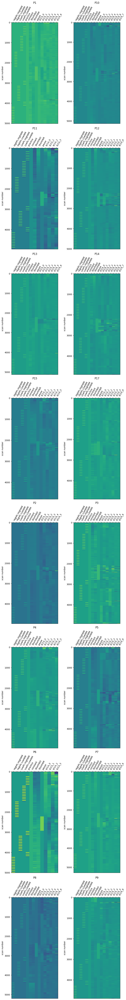

In [3]:
n_cols = 2
n = len(design_matrices)
n_rows = int(np.ceil(n / n_cols))

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(4 * n_cols, 8 * n_rows),
    constrained_layout=True
)

# Flatten axes array for easy iteration
axes = np.array(axes).reshape(-1)

# Plot each matrix
for ax, matrix, subject in zip(axes, design_matrices, all_subjects):
    plot_design_matrix(matrix, axes=ax)
    ax.set_title(subject)

for ax in axes[len(design_matrices):]:
    ax.axis("off")

plt.show()

# Adjust alignment for an example design matrix

Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Shifting onsets -10 seconds
Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Shifting onsets 0 seconds
Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Shifting onsets 10 seconds


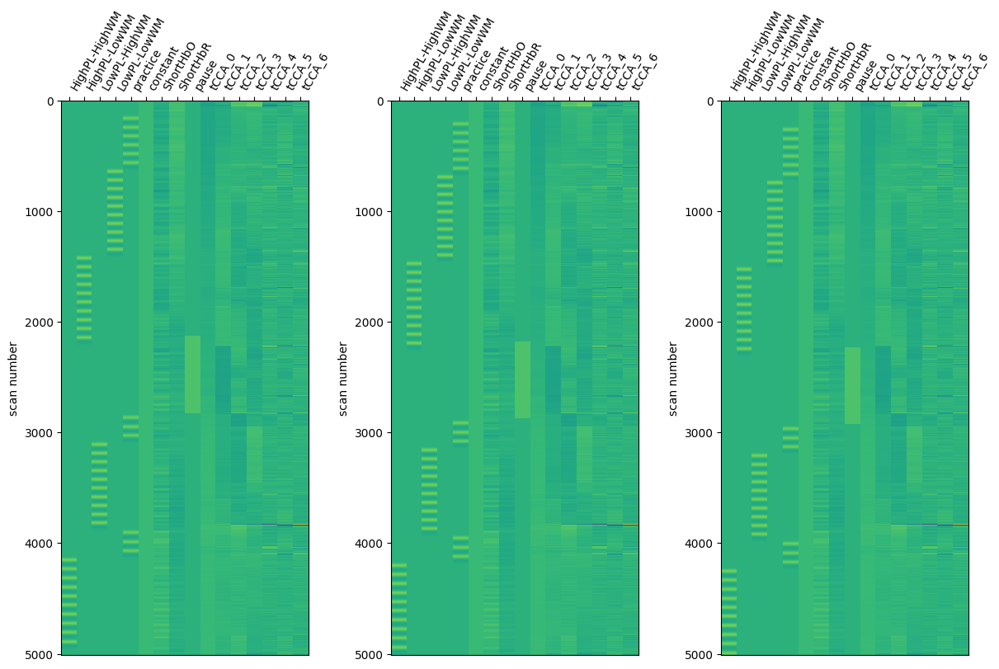

In [4]:
# Show effect of maximum shifts
onset_shifts = [-10, 0, 10]

# Get all subjects in a sorted list
all_subjects = [file.subject for file in nirs_files]
all_subjects = sorted(list(set(all_subjects)))

# Illustrate each design matrix
subject = all_subjects[0]

design_matrices = []
for onset_shift in onset_shifts:
    
    # Get SNIRF file for this subject
    bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)
    
    print(f"Processing {bids_path}..")
    if not os.path.exists(bids_path):
        print(f"No SNIRF file, skip: {bids_path}")
        continue

    # Raw data
    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path, verbose="ERROR")
    long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
    short_chs = mne_nirs.channels.get_short_channels(raw_intensity)
    raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
    raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)
    raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
    raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)
    
    # Adjust onsets
    print(f"Shifting onsets {onset_shift} seconds")

    annot = raw_haemo_long.annotations
    
    new_annot = mne.Annotations(
        onset=annot.onset + onset_shift,
        duration=annot.duration,
        description=annot.description    )
    
    raw_haemo_long.set_annotations(new_annot)
    
    
    onsets = raw_haemo_long.annotations.onset
    durations = raw_haemo_long.annotations.duration

    # Where to store results from the GLM analysis
    glm_fname = f"{glm_folder}/{subject}_glm.h5"

    # Create a design matrix
    design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                                stim_dur=5,
                                                                                drift_model=None,
                                                                                hrf_model="glover")
    design_matrix["ShortHbO"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
    )
    design_matrix["ShortHbR"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
    )    
    ends = onsets + durations
    gaps = onsets[1:] - ends[:-1]    
    pause_idx = np.argmax(gaps)
    pause_start_sec = ends[pause_idx]
    pause_stop_sec = onsets[pause_idx+1]    
    pause_regressor = np.zeros(len(raw_haemo_long.times))
    start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
    stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
    pause_regressor[start_idx:stop_idx] = 1.0
    design_matrix["pause"] = pause_regressor

    # Add acceleration regressors via TCCA
    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
    aux_all = aux_df.to_numpy()
    nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T
    reg, tcca_info = mne_nirs.experimental_design.rtcca(
        nirs_data,
        aux_all,
        tau=1,
        n_emb=3,
        ct=0.4,
        pca_fnirs = False,
        pca_aux = True,
        shrink=True
    )
    reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
    for i, name in zip(range(reg.shape[1]), reg_names):
        design_matrix[name] = reg[:, i]

    # Plot final matrix
    #fig = plot_design_matrix(design_matrix)
    #plt.show()
    design_matrices.append(design_matrix)

n_cols = 3
n = len(design_matrices)
n_rows = int(np.ceil(n / n_cols))

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(4 * n_cols, 8 * n_rows),
    constrained_layout=True
)

# Flatten axes array for easy iteration
axes = np.array(axes).reshape(-1)

# Plot each matrix
for ax, matrix in zip(axes, design_matrices):
    plot_design_matrix(matrix, axes=ax)

for ax in axes[len(design_matrices):]:
    ax.axis("off")

plt.show()

# ROI setup

In [5]:
# ROI channel pair definitions (SRC, DET) from fOLD v2.2 (specificity 30%)
roi_dlpfc_ba9       = [[4, 5], [4, 2], [4, 4], [7, 5], [1, 2], [11, 9], [13, 13]]
roi_dlpfc_ba46      = [[2, 1], [8, 7]]
roi_frontopolar_ba10 = [[5, 4], [3, 4], [6, 4], [3, 3], [6, 6], [5, 3], [5, 6], [8, 6], [2, 3]]
roi_fef_ba8         = [[13, 2], [11, 5], [4, 2], [4, 5]]

roi_ba9_pairs  = {tuple(p) for p in roi_dlpfc_ba9}
roi_ba46_pairs = {tuple(p) for p in roi_dlpfc_ba46}
roi_ba10_pairs = {tuple(p) for p in roi_frontopolar_ba10}
roi_ba8_pairs  = {tuple(p) for p in roi_fef_ba8}

def assign_roi(row):
    pair = (row["Source"], row["Detector"])
    if pair in roi_ba9_pairs:
        return "BA9"
    elif pair in roi_ba46_pairs:
        return "BA46"
    elif pair in roi_ba10_pairs:
        return "BA10"
    elif pair in roi_ba8_pairs:
        return "BA8"
    else:
        return "Other"

# Robustness sweep: onset shifts −10 to +10 s

In [6]:
onset_shifts = list(range(-9, 10))  # -5, -4, ..., 0, ..., 4, 5
all_results = {}   # keyed by onset_shift
raw_ref = None     # reference raw object (channel positions) for plotting

all_subjects = sorted({f.subject for f in nirs_files})

for onset_shift in onset_shifts:
    print(f"\n{'='*55}")
    print(f"  Onset shift: {onset_shift:+d} s")
    print(f"{'='*55}")

    roi_frames = []
    cha_frames = []

    for subject in all_subjects:
        bids_path = mne_bids.BIDSPath(
            subject=subject, task=task,
            suffix=datatype, datatype=datatype, root=bids_root
        )
        if not os.path.exists(bids_path):
            print(f"  Skip {subject}: file not found")
            continue

        raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path, verbose="ERROR")
        long_chs  = mne_nirs.channels.get_long_channels(raw_intensity)
        short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

        raw_od_long  = mne.preprocessing.nirs.optical_density(long_chs)
        raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)

        # Channel quality
        sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od_long)
        bad_channels_raw = list(compress(raw_od_long.ch_names, sci < sci_limit))
        bad_channels = np.unique(
            [ch.replace(" 760", "").replace(" 850", "") for ch in bad_channels_raw]
        ).tolist()

        raw_haemo_long  = mne.preprocessing.nirs.beer_lambert_law(raw_od_long,  ppf=0.1)
        raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

        # Capture channel positions from the first subject (shift-independent)
        if raw_ref is None:
            raw_ref = raw_haemo_long.copy()

        # Apply onset shift
        ann = raw_haemo_long.annotations
        raw_haemo_long.set_annotations(mne.Annotations(
            onset=ann.onset + onset_shift,
            duration=ann.duration,
            description=ann.description,
        ))

        # Design matrix (cosine drift, same as perceptual_notebook)
        design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(
            raw_haemo_long, stim_dur=5,
            drift_model="cosine", hrf_model="glover", high_pass=0.034
        )
        design_matrix["ShortHbO"] = np.mean(
            raw_haemo_short.copy().pick("hbo").get_data(), axis=0)
        design_matrix["ShortHbR"] = np.mean(
            raw_haemo_short.copy().pick("hbr").get_data(), axis=0)

        # Pause regressor (longest inter-trial gap)
        onsets    = raw_haemo_long.annotations.onset
        durations = raw_haemo_long.annotations.duration
        ends      = onsets + durations
        gaps      = onsets[1:] - ends[:-1]
        pause_idx = np.argmax(gaps)
        pause_reg = np.zeros(len(raw_haemo_long.times))
        pause_reg[
            np.searchsorted(raw_haemo_long.times, ends[pause_idx]):
            np.searchsorted(raw_haemo_long.times, onsets[pause_idx + 1])
        ] = 1.0
        design_matrix["pause"] = pause_reg

        # tCCA motion regressors
        aux_df    = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
        nirs_data = raw_haemo_long.copy().pick("hbo").get_data().T
        reg, _ = mne_nirs.experimental_design.rtcca(
            nirs_data, aux_df.to_numpy(),
            tau=1, n_emb=3, ct=0.4,
            pca_fnirs=False, pca_aux=True, shrink=True
        )
        for i in range(reg.shape[1]):
            design_matrix[f"tCCA_{i}"] = reg[:, i]

        # GLM
        glm_est = mne_nirs.statistics.run_glm(raw_haemo_long, design_matrix, noise_model="auto")

        # Channel-level dataframe
        cha = glm_est.to_dataframe()
        cha["ROI"] = cha.apply(assign_roi, axis=1)
        cha["channel_ok"] = cha["ch_name"].apply(lambda x: x.split(" ")[0] not in bad_channels)

        # ROI-level dataframe (exclude bad channels from ROI averages)
        all_bad_idx = []
        for bad_ch in bad_channels:
            src = bad_ch.split("_")[0].replace("S", "")
            det = bad_ch.split("_")[1].replace("D", "")
            all_bad_idx.extend(
                mne_nirs.channels.picks_pair_to_idx(raw_haemo_long, [[src, det]], on_missing="error")
            )
        roi_dict = {
            "dlpfc_ba9":         [x for x in mne_nirs.channels.picks_pair_to_idx(raw_haemo_long, roi_dlpfc_ba9,        on_missing="error") if x not in all_bad_idx],
            "dlpfc_ba46":        [x for x in mne_nirs.channels.picks_pair_to_idx(raw_haemo_long, roi_dlpfc_ba46,       on_missing="error") if x not in all_bad_idx],
            "frontopolar_ba10":  [x for x in mne_nirs.channels.picks_pair_to_idx(raw_haemo_long, roi_frontopolar_ba10, on_missing="error") if x not in all_bad_idx],
            "fef_ba8":           [x for x in mne_nirs.channels.picks_pair_to_idx(raw_haemo_long, roi_fef_ba8,          on_missing="error") if x not in all_bad_idx],
        }
        roi = glm_est.to_dataframe_region_of_interest(roi_dict, glm_est.design.columns, demographic_info=True)

        cha["subject"] = roi["subject"] = subject
        cha_frames.append(cha)
        roi_frames.append(roi)

        print(f"  {subject} done (bad channels: {bad_channels})")

    all_results[onset_shift] = {
        "cha_data": pd.concat(cha_frames, ignore_index=True),
        "roi_data": pd.concat(roi_frames, ignore_index=True),
    }

print("\nRobustness sweep complete.")


  Onset shift: -9 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
  P1 done (bad channels: [])
Reading 0 ... 5134  =      0.000 ...  1009.385 secs...
Reading 0 ... 5134  =      0.000 ...  1009.385 secs...
  P10 done (bad channels: ['S4_D2'])
Reading 0 ... 4953  =      0.000 ...   973.799 secs...
Reading 0 ... 4953  =      0.000 ...   973.799 secs...
  P11 done (bad channels: [])
Reading 0 ... 5016  =      0.000 ...   986.186 secs...
Reading 0 ... 5016  =      0.000 ...   986.186 secs...
  P12 done (bad channels: [])
Reading 0 ... 5133  =      0.000 ...  1009.189 secs...
Reading 0 ... 5133  =      0.000 ...  1009.189 secs...
  P13 done (bad channels: ['S9_D9'])
Reading 0 ... 4904  =      0.000 ...   964.166 secs...
Reading 0 ... 4904  =      0.000 ...   964.166 secs...
  P14 done (bad channels: ['S15_D13', 'S1_D13', 'S9_D9'])
Reading 0 ... 4796  =      0.000 ...   942.932 secs...
Reading 0 ... 4796  =      0.000 ...   942.

/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P4 done (bad channels: ['S11_D5'])
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
  P5 done (bad channels: ['S10_D10', 'S11_D5', 'S11_D9', 'S12_D10', 'S12_D11', 'S13_D12', 'S14_D12'])
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
  P6 done (bad channels: [])
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
  P7 done (bad channels: [])
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
  P8 done (bad channels: [])
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
  P9 done (bad channels: ['S16_D13'])

  Onset shift: +7 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
  P1 done (bad channels: [])
Reading 0 ... 5134  =     

/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P4 done (bad channels: ['S11_D5'])
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
  P5 done (bad channels: ['S10_D10', 'S11_D5', 'S11_D9', 'S12_D10', 'S12_D11', 'S13_D12', 'S14_D12'])
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
  P6 done (bad channels: [])
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
  P7 done (bad channels: [])
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
  P8 done (bad channels: [])
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
  P9 done (bad channels: ['S16_D13'])

  Onset shift: +8 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
  P1 done (bad channels: [])
Reading 0 ... 5134  =     

/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P14 done (bad channels: ['S15_D13', 'S1_D13', 'S9_D9'])
Reading 0 ... 4796  =      0.000 ...   942.932 secs...
Reading 0 ... 4796  =      0.000 ...   942.932 secs...
  P15 done (bad channels: ['S10_D10', 'S11_D5', 'S12_D10', 'S13_D13', 'S13_D2', 'S14_D12', 'S14_D14', 'S15_D14', 'S1_D13', 'S1_D2', 'S7_D5', 'S7_D9'])
Reading 0 ... 4896  =      0.000 ...   962.593 secs...
Reading 0 ... 4896  =      0.000 ...   962.593 secs...
  P17 done (bad channels: [])
Reading 0 ... 4980  =      0.000 ...   979.108 secs...
Reading 0 ... 4980  =      0.000 ...   979.108 secs...
  P2 done (bad channels: ['S10_D10', 'S11_D11', 'S11_D5', 'S12_D10', 'S13_D12', 'S14_D12', 'S14_D14', 'S15_D12', 'S15_D13', 'S15_D14'])
Reading 0 ... 4922  =      0.000 ...   967.705 secs...
Reading 0 ... 4922  =      0.000 ...   967.705 secs...
  P3 done (bad channels: ['S1_D13'])
Reading 0 ... 4921  =      0.000 ...   967.508 secs...
Reading 0 ... 4921  =      0.000 ...   967.508 secs...


/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P4 done (bad channels: ['S11_D5'])
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
  P5 done (bad channels: ['S10_D10', 'S11_D5', 'S11_D9', 'S12_D10', 'S12_D11', 'S13_D12', 'S14_D12'])
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
  P6 done (bad channels: [])
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
  P7 done (bad channels: [])
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
  P8 done (bad channels: [])
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
  P9 done (bad channels: ['S16_D13'])

  Onset shift: +9 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
  P1 done (bad channels: [])
Reading 0 ... 5134  =     

/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P14 done (bad channels: ['S15_D13', 'S1_D13', 'S9_D9'])
Reading 0 ... 4796  =      0.000 ...   942.932 secs...
Reading 0 ... 4796  =      0.000 ...   942.932 secs...
  P15 done (bad channels: ['S10_D10', 'S11_D5', 'S12_D10', 'S13_D13', 'S13_D2', 'S14_D12', 'S14_D14', 'S15_D14', 'S1_D13', 'S1_D2', 'S7_D5', 'S7_D9'])
Reading 0 ... 4896  =      0.000 ...   962.593 secs...
Reading 0 ... 4896  =      0.000 ...   962.593 secs...
  P17 done (bad channels: [])
Reading 0 ... 4980  =      0.000 ...   979.108 secs...
Reading 0 ... 4980  =      0.000 ...   979.108 secs...
  P2 done (bad channels: ['S10_D10', 'S11_D11', 'S11_D5', 'S12_D10', 'S13_D12', 'S14_D12', 'S14_D14', 'S15_D12', 'S15_D13', 'S15_D14'])
Reading 0 ... 4922  =      0.000 ...   967.705 secs...
Reading 0 ... 4922  =      0.000 ...   967.705 secs...
  P3 done (bad channels: ['S1_D13'])
Reading 0 ... 4921  =      0.000 ...   967.508 secs...
Reading 0 ... 4921  =      0.000 ...   967.508 secs...


/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P4 done (bad channels: ['S11_D5'])
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
Reading 0 ... 4950  =      0.000 ...   973.210 secs...
  P5 done (bad channels: ['S10_D10', 'S11_D5', 'S11_D9', 'S12_D10', 'S12_D11', 'S13_D12', 'S14_D12'])
Reading 0 ... 5004  =      0.000 ...   983.826 secs...
Reading 0 ... 5004  =      0.000 ...   983.826 secs...


/var/folders/m4/lwl45ymj7ygb_w4t_xhm9d6c0000gp/T/ipykernel_76116/1805745841.py:47: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_haemo_long.set_annotations(mne.Annotations(


  P6 done (bad channels: [])
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
Reading 0 ... 5286  =      0.000 ...  1039.270 secs...
  P7 done (bad channels: [])
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
Reading 0 ... 5204  =      0.000 ...  1023.148 secs...
  P8 done (bad channels: [])
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
Reading 0 ... 4897  =      0.000 ...   962.789 secs...
  P9 done (bad channels: ['S16_D13'])

Robustness sweep complete.


# Group-level topoplots per shift

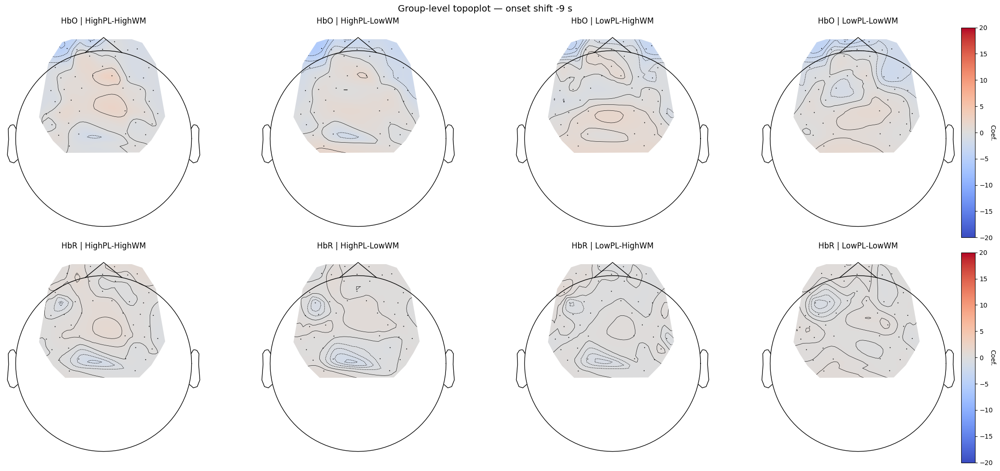

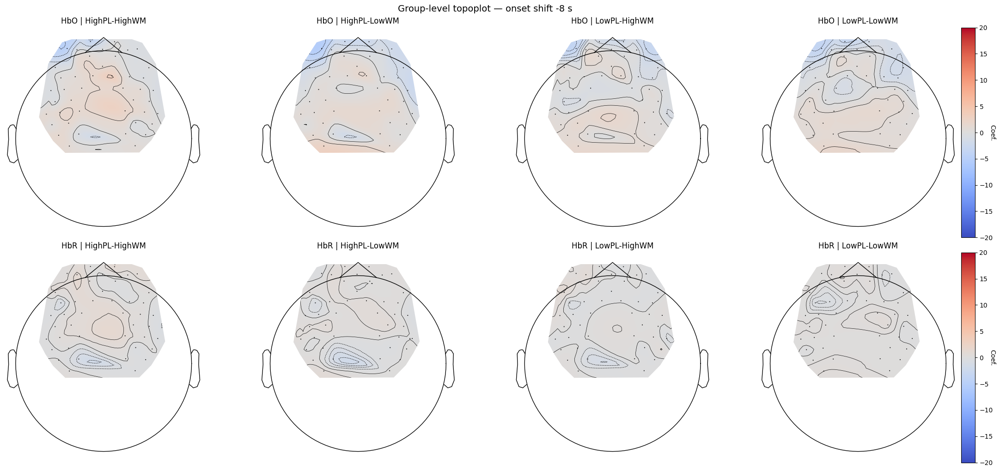

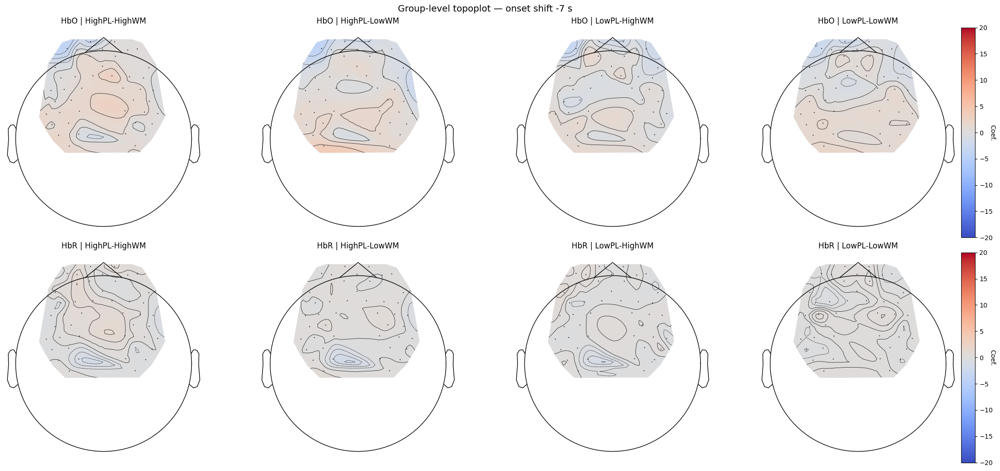

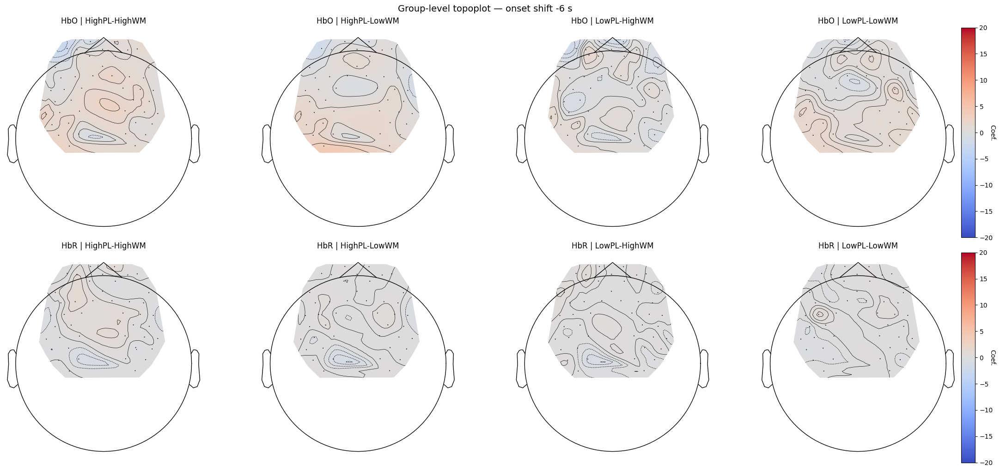

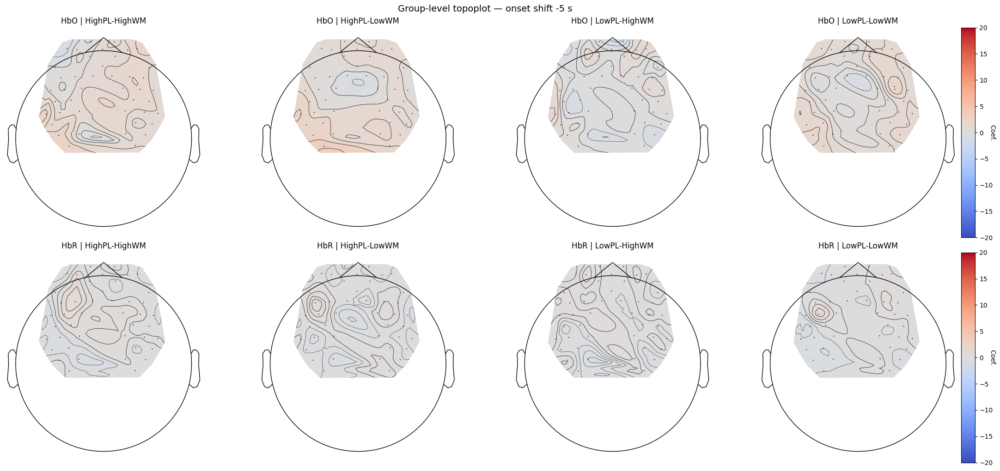

...

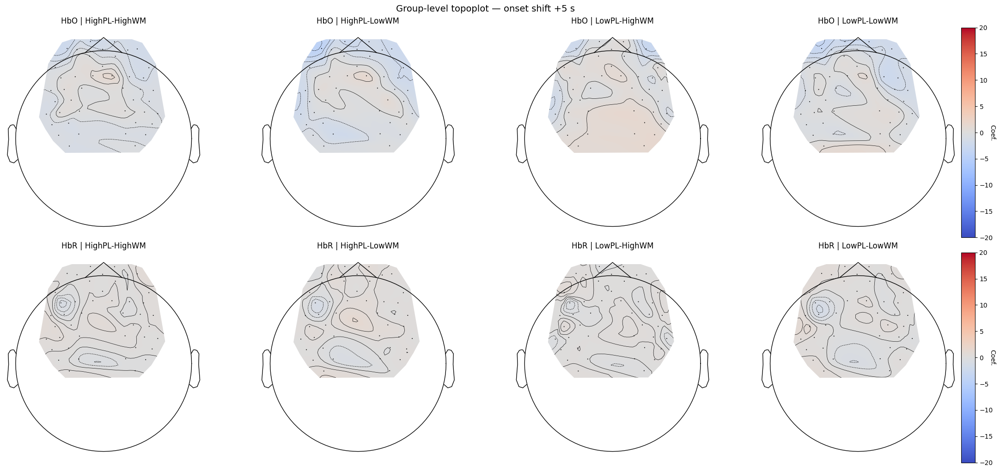

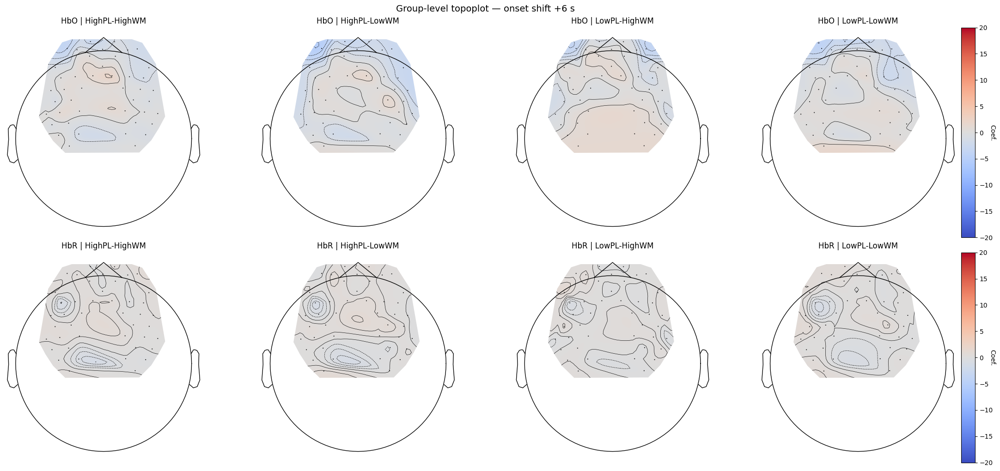

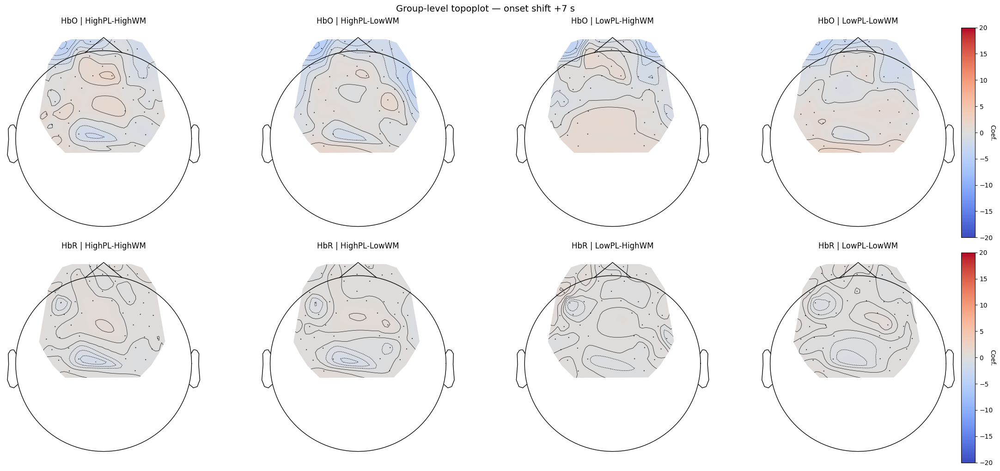

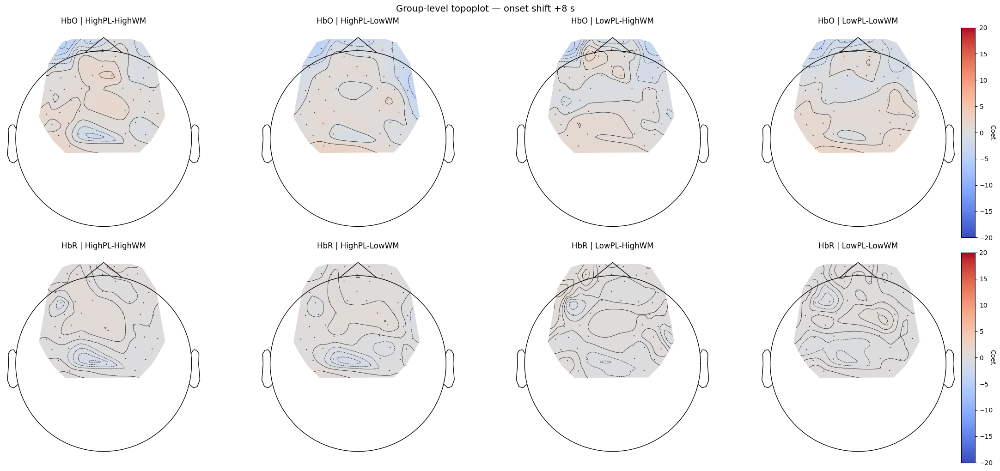

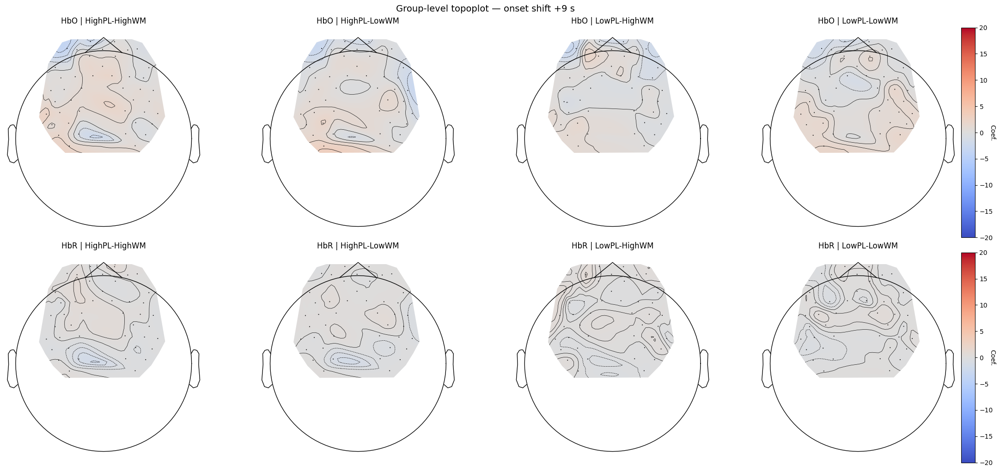

In [7]:
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']

# One figure per shift: HbO top row, HbR bottom row, one column per condition
for onset_shift in onset_shifts:
    cha_data = all_results[onset_shift]['cha_data']

    fig, axes = plt.subplots(2, 4, figsize=(22, 10), constrained_layout=True)
    fig.suptitle(f"Group-level topoplot — onset shift {onset_shift:+d} s", fontsize=14)

    for row_idx, chroma in enumerate(['hbo', 'hbr']):
        ch_sub = cha_data.query("Condition in @conditions and Chroma == @chroma").copy()
        ch_sub["theta"] = ch_sub["theta"] * 1e6

        model = smf.mixedlm(
            "theta ~ -1 + ch_name:Chroma:Condition",
            ch_sub, groups=ch_sub["subject"]
        ).fit(method='nm', disp=False)

        ch_df = mne_nirs.statistics.statsmodels_to_results(
            model, order=raw_ref.copy().pick(chroma).ch_names
        )

        for col_idx, cond in enumerate(conditions):
            df_cond = ch_df.query(f"Condition == '{cond}'")
            mne_nirs.visualisation.plot_glm_group_topo(
                raw_ref.copy().pick(chroma),
                df_cond,
                colorbar=(col_idx == len(conditions) - 1),
                axes=axes[row_idx, col_idx],
                vlim=(-20, 20),
                cmap=mpl.cm.coolwarm,
                threshold=False,
            )
            label = "HbO" if chroma == "hbo" else "HbR"
            axes[row_idx, col_idx].set_title(f"{label} | {cond}")

    plt.show()

# Group-level ROI statistics per shift

In [8]:
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
theta_records = []

for onset_shift in onset_shifts:
    roi_data = all_results[onset_shift]['roi_data']
    subj_roi = roi_data.query("Condition in @conditions").copy()
    subj_roi["theta"] = subj_roi["theta"] * 1e6

    print(f"\n{'='*60}")
    print(f"  ROI statistics — onset shift {onset_shift:+d} s")
    print(f"{'='*60}")

    for chroma, label in [('hbo', 'HbO'), ('hbr', 'HbR')]:
        roi_sub = subj_roi.query("Chroma == @chroma")
        model = smf.mixedlm(
            "theta ~ -1 + ROI:Condition",
            roi_sub, groups=roi_sub["subject"]
        ).fit(method='nm', disp=False)

        df = mne_nirs.statistics.statsmodels_to_results(model)
        df['onset_shift'] = onset_shift
        df['Chroma'] = chroma
        theta_records.append(df)

        sig = df[df["Significant"] == True][["ROI", "Condition", "Coef.", "P>|z|"]]
        print(f"\n  {label}:")
        if len(sig) > 0:
            print(sig.to_string())
        else:
            print("  (no significant ROIs)")

theta_df = pd.concat(theta_records, ignore_index=True)
print("\nDone.")


  ROI statistics — onset shift -9 s

  HbO:
                                                            ROI      Condition     Coef.     P>|z|
ROI[fef_ba8]:Condition[HighPL-HighWM]                   fef_ba8  HighPL-HighWM  1.365117  0.049668
ROI[dlpfc_ba46]:Condition[HighPL-LowWM]              dlpfc_ba46   HighPL-LowWM -1.910893  0.006004
ROI[frontopolar_ba10]:Condition[HighPL-LowWM]  frontopolar_ba10   HighPL-LowWM -1.683781  0.015478
ROI[dlpfc_ba46]:Condition[LowPL-LowWM]               dlpfc_ba46    LowPL-LowWM -1.502850  0.030707

  HbR:
                                           ROI      Condition     Coef.     P>|z|
ROI[fef_ba8]:Condition[HighPL-HighWM]  fef_ba8  HighPL-HighWM  0.555799  0.033649

  ROI statistics — onset shift -8 s

  HbO:
                                                ROI      Condition     Coef.     P>|z|
ROI[fef_ba8]:Condition[HighPL-HighWM]       fef_ba8  HighPL-HighWM  1.569366  0.031629
ROI[dlpfc_ba46]:Condition[HighPL-LowWM]  dlpfc_ba46   HighPL-LowWM -1

# Distribution of theta estimates across shifts

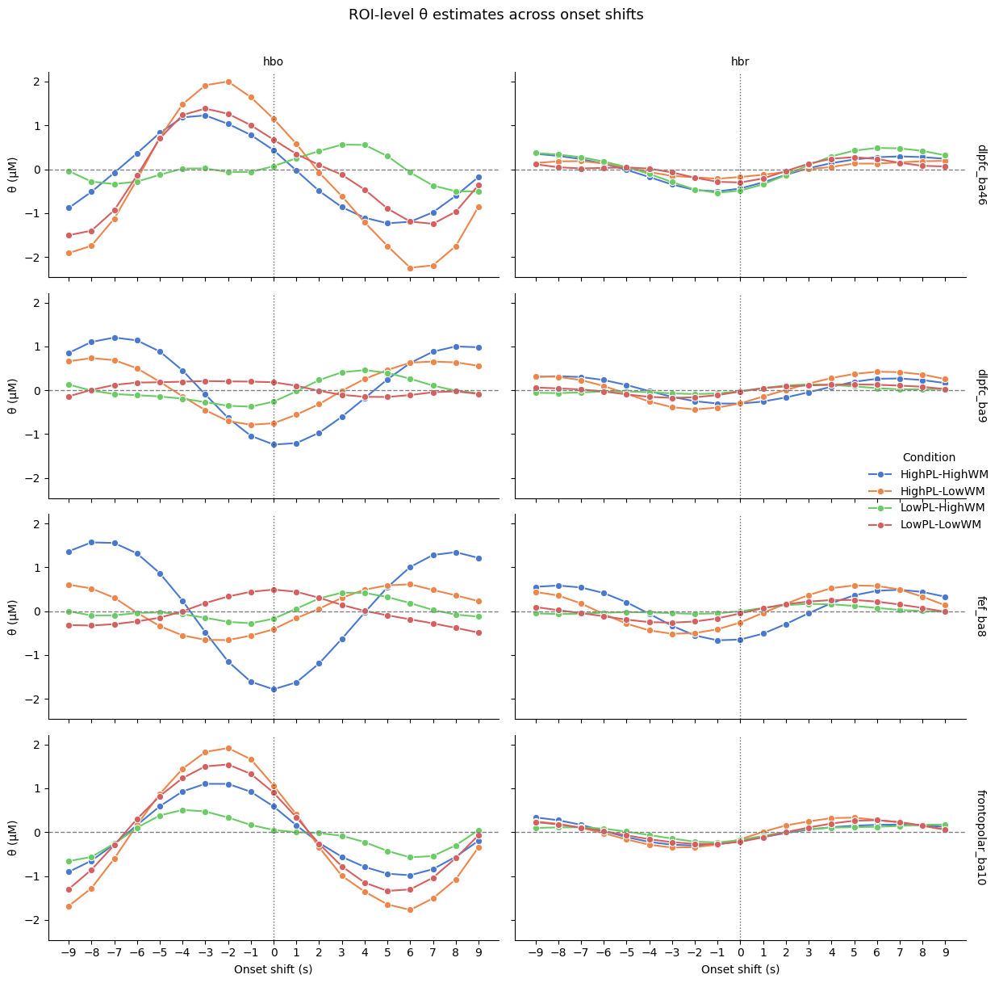

In [9]:
# Distribution of ROI theta estimates vs onset shift
g = sns.FacetGrid(
    theta_df,
    row="ROI",
    col="Chroma",
    height=3,
    aspect=1.8,
    sharey=True,
    margin_titles=True,
)
g.map_dataframe(
    sns.lineplot,
    x="onset_shift",
    y="Coef.",
    hue="Condition",
    palette="muted",
    marker="o",
    markersize=6,
)
g.add_legend(title="Condition")

for ax in g.axes.flat:
    ax.axhline(0, linestyle="--", color="gray", linewidth=1)
    ax.axvline(0, linestyle=":", color="black", linewidth=1, alpha=0.6)
    ax.set_xlabel("Onset shift (s)")
    ax.set_ylabel("θ (µM)")
    ax.set_xticks(onset_shifts)

g.set_titles(row_template="{row_name}", col_template="{col_name}")
g.figure.suptitle("ROI-level θ estimates across onset shifts", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()